# 02 · SARIMA, pronóstico y backtesting

**Descargo metodológico:** las bandas y pronósticos describen la incertidumbre del proceso generador de datos estimado. No constituyen una predicción de insolvencia.

Se replica el modelo SARIMA seleccionado para la serie, se grafica el ajuste dentro de la muestra, el pronóstico a 12 meses con bandas 80 % y 95 %, y se compara el RMSE contra los baselines Naive y Seasonal Naive.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def raiz_proyecto():
    actual = Path.cwd()
    for base in [actual, *actual.parents]:
        if (base / "dashboard" / "data.json").exists():
            return base
    raise FileNotFoundError("Ejecute el notebook desde el repositorio del proyecto")

ROOT = raiz_proyecto()
datos = json.loads((ROOT / "dashboard" / "data.json").read_text(encoding="utf-8"))
BANCO = "bfort"
INDICADOR = "mora"
banco = next(b for b in datos["bancos"] if b["id"] == BANCO)
meta_indicador = next(i for i in datos["indicadores_meta"] if i["id"] == INDICADOR)
serie = datos["series"][BANCO][INDICADOR]
tabla = pd.DataFrame({
    "fecha": pd.to_datetime(serie["fechas"]),
    "valor": serie["observado"],
}).set_index("fecha")
tabla.head()

,valor
fecha,
2019-01-01,1.668071
2019-02-01,2.277313
2019-03-01,2.143988
2019-04-01,2.250342
2019-05-01,1.905817


## Modelo seleccionado

In [2]:
sa = serie["sarima"]
print("Orden:", tuple(sa["orden"]))
print("Orden estacional:", tuple(sa["orden_estacional"]))
print("AIC:", round(sa["aic"], 4))
print("BIC:", round(sa["bic"], 4))
print("Modelos evaluados:", sa["modelos_evaluados"])

pd.DataFrame(sa["top3_modelos"])

Orden: (0, 1, 0)
Orden estacional: (1, 0, 0, 12)
AIC: 15.2863
BIC: 19.8117
Modelos evaluados: 24


,orden,orden_estacional,aic,bic
0,"[0, 1, 0]","[1, 0, 0, 12]",15.286339,19.811699
1,"[0, 1, 1]","[1, 0, 0, 12]",16.923842,23.711881
2,"[0, 1, 0]","[0, 0, 1, 12]",17.004991,21.501981


## Reestimación con statsmodels

In [3]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

modelo = SARIMAX(
    tabla["valor"].astype(float),
    order=tuple(sa["orden"]),
    seasonal_order=tuple(sa["orden_estacional"]),
    enforce_stationarity=False,
    enforce_invertibility=False,
)
ajuste = modelo.fit(disp=False, maxiter=50)
print(ajuste.summary().tables[0])

C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                              valor   No. Observations:                   84
Model:             SARIMAX(0, 1, 0)x(1, 0, 0, 12)   Log Likelihood                  -5.643
Date:                            Sun, 15 Nov 2026   AIC                             15.286
Time:                                    11:16:36   BIC                             19.812
Sample:                                01-01-2019   HQIC                            17.086
                                     - 12-01-2025                                         
Covariance Type:                              opg                                         


## Ajuste, pronóstico y bandas

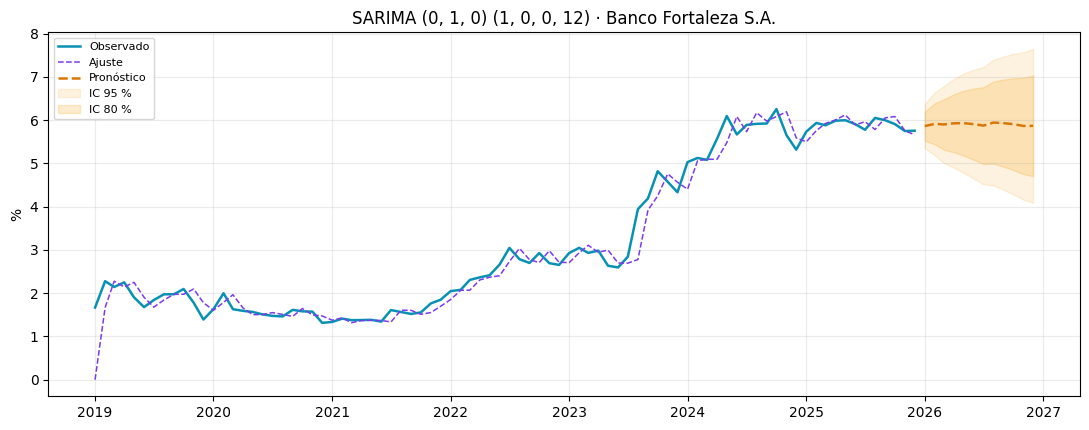

In [4]:
pron = serie["pronostico"]
fechas_pron = pd.to_datetime(pron["fechas"])
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(tabla.index, tabla["valor"], color="#0891b2", linewidth=1.8, label="Observado")
ax.plot(tabla.index, serie["ajuste_in_sample"], color="#7c3aed", linewidth=1.1, linestyle="--", label="Ajuste")
ax.plot(fechas_pron, pron["media"], color="#d97706", linewidth=1.8, linestyle="--", label="Pronóstico")
ax.fill_between(fechas_pron, pron["ic95_inf"], pron["ic95_sup"], color="#f59e0b", alpha=0.13, label="IC 95 %")
ax.fill_between(fechas_pron, pron["ic80_inf"], pron["ic80_sup"], color="#f59e0b", alpha=0.20, label="IC 80 %")
ax.set_title(f"SARIMA {tuple(sa['orden'])} {tuple(sa['orden_estacional'])} · {banco['nombre']}")
ax.set_ylabel("%")
ax.legend(loc="upper left", fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Backtesting walk-forward contra baselines

In [5]:
bt = serie["backtest"]
tabla_bt = pd.DataFrame({
    "Métrica": ["RMSE", "MAE", "sMAPE"],
    "Modelo": [bt["rmse_modelo"], bt["mae_modelo"], bt["smape_modelo"]],
    "Naive": [bt["rmse_naive"], np.nan, np.nan],
    "Seasonal Naive": [bt["rmse_snaive"], np.nan, np.nan],
})
tabla_bt

,Métrica,Modelo,Naive,Seasonal Naive
0,RMSE,0.147640,0.174084,0.445817
1,MAE,0.121064,NaN,NaN
2,sMAPE,2.063133,NaN,NaN


In [6]:
mejora = (bt["rmse_naive"] - bt["rmse_modelo"]) / bt["rmse_naive"] * 100
print("¿Supera a Naive?", bt["supera_baseline"])
print("Mejora relativa en RMSE:", round(mejora, 2), "%")
print("Observaciones de evaluación:", bt["observaciones_eval"])

¿Supera a Naive? True
Mejora relativa en RMSE: 15.19 %
Observaciones de evaluación: 12


## Lectura para la defensa

- El modelo se selecciona por AIC, pero se evalúa fuera de muestra con ventana expansiva.
- Si `supera_baseline` es falso, se reporta sin ocultarlo. En 84 series, el SARIMA supera a Naive en 26; la comparación honesta es parte del valor académico.
- Las bandas al 80 % y 95 % no son intervalos de confianza de los parámetros: son intervalos de predicción del proceso estimado.